In [4]:
import pandas as pd
import importlib
import joblib
from ufc_betting.config import settings
from ufc_betting.Models.LineMovement import conditional_price_density

importlib.reload(conditional_price_density)


<module 'ufc_betting.Models.LineMovement.conditional_price_density' from 'C:\\Users\\jcmar\\my_files\\SportsBetting\\src\\ufc_betting\\Models\\LineMovement\\conditional_price_density.py'>

In [5]:
def train_density_model(df, days_out=6, odds_type="close1", bw="cv_ml"):
    """Fit supplied rows with opening, closing, price columns; no split selection."""
    return conditional_price_density.fit_price_density(
        df, days_out=days_out, odds_type=odds_type, bw=bw,
    )


def plot_density(model, opening_odds, closing_odds):
    """Plot p(intermediate | open, close) using an already-fitted estimator."""
    return conditional_price_density.plot_price_density(model, opening_odds, closing_odds)


In [6]:
# Choose "load" to reuse saved models or "train" to fit new models.
model_mode = "load"
save_trained_models = True
bandwidth = "cv_ml"
days_out_values = (7, 6, 5)
markets = ("close1", "close2")
observations_dir = settings.data_dir / "images" / "conditional_day_price_density"
models_dir = settings.saved_models_dir
# To load/save the separate test models, use ..._{day}_days_test.joblib.
model_filename = "conditional_price_density_{market}_{day}_days.joblib"

if model_mode not in {"load", "train"}:
    raise ValueError('model_mode must be "load" or "train"')
model_paths = {
    day: {market: models_dir / model_filename.format(market=market, day=day)
          for market in markets}
    for day in days_out_values
}
training_data = {}
if model_mode == "load":
    missing = [str(path) for paths in model_paths.values() for path in paths.values()
               if not path.is_file()]
    if missing:
        raise FileNotFoundError("Saved models missing; set model_mode='train' or fix model_filename:\n" + "\n".join(missing))
    fitted_models = {
        day: {market: joblib.load(path) for market, path in paths.items()}
        for day, paths in model_paths.items()
    }
    for day, models in fitted_models.items():
        for market, fitted in models.items():
            required = {"model", "observations", "bandwidths", "days_out", "odds_type"}
            if not isinstance(fitted, dict) or not required.issubset(fitted):
                raise ValueError(f"Invalid saved density model: {model_paths[day][market]}")
            if fitted["days_out"] != day or fitted["odds_type"] != market:
                raise ValueError(f"Saved model day/market mismatch: {model_paths[day][market]}")
else:
    # Observation CSVs are needed only when training.
    training_data = {
        day: {market: pd.read_csv(observations_dir / f"{market}_{day}_day_observations.csv")
              for market in markets}
        for day in days_out_values
    }
    fitted_models = {
        day: {market: train_density_model(df, days_out=day, odds_type=market, bw=bandwidth)
              for market, df in datasets.items()}
        for day, datasets in training_data.items()
    }

In [7]:
# Loading never overwrites saved models. Training saves only when enabled.
summary_rows = []
for day, models in fitted_models.items():
    for market, fitted in models.items():
        path = model_paths[day][market]
        if model_mode == "train" and save_trained_models:
            path.parent.mkdir(parents=True, exist_ok=True)
            joblib.dump(fitted, path)
        summary_rows.append({
            "days_out": day, "odds_type": market, "mode": model_mode,
            "observations": len(fitted["observations"]),
            "bandwidths": fitted["bandwidths"], "model_path": str(path),
            "saved_this_run": model_mode == "train" and save_trained_models,
        })
density_summary = pd.DataFrame(summary_rows)
display(density_summary)

,days_out,odds_type,mode,observations,bandwidths,model_path,saved_this_run
0,7,close1,load,386,"[0.14736342107100703, 0.11430338339771869, 0.2...",C:\Users\jcmar\my_files\SportsBetting\Data\sav...,False
1,7,close2,load,386,"[0.14646818855080035, 0.062243327006875036, 0....",C:\Users\jcmar\my_files\SportsBetting\Data\sav...,False
2,6,close1,load,428,"[0.1381978713236055, 0.09986517901372513, 0.21...",C:\Users\jcmar\my_files\SportsBetting\Data\sav...,False
3,6,close2,load,428,"[0.13900949547263713, 0.06512188842982318, 0.1...",C:\Users\jcmar\my_files\SportsBetting\Data\sav...,False
4,5,close1,load,414,"[0.1689046589791849, 0.08308485268662272, 0.18...",C:\Users\jcmar\my_files\SportsBetting\Data\sav...,False
5,5,close2,load,414,"[0.13185573950912205, 0.0669996369195231, 0.17...",C:\Users\jcmar\my_files\SportsBetting\Data\sav...,False


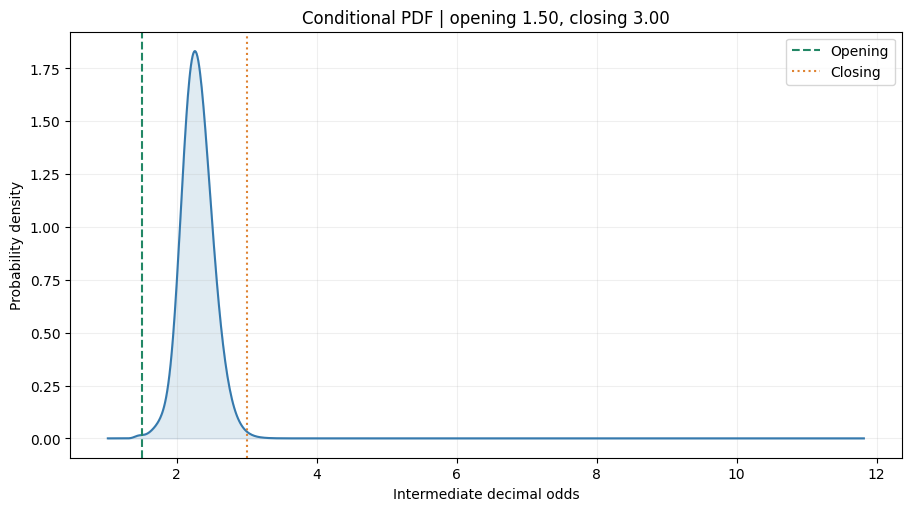

In [9]:
# Select a fitted day/market and query odds; plotting does not retrain.
day, market = 7, "close1"
fig, ax = plot_density(
    fitted_models[day][market]["model"], opening_odds=1.5, closing_odds=3.0,
)


In [ ]:
# A second plot from the selected load/train run; no disk reload or retraining.
fig, ax = plot_density(fitted_models[5]["close2"]["model"], opening_odds=3.0, closing_odds=2.2)

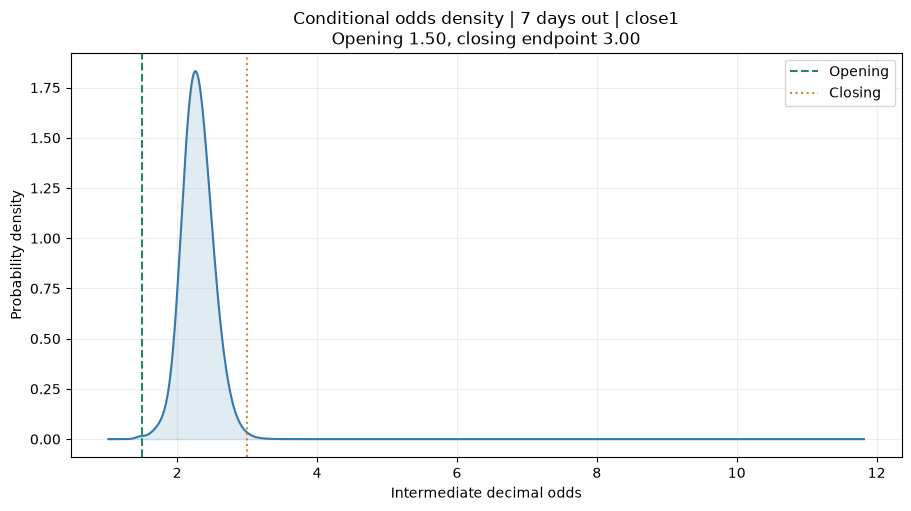

In [ ]:
# Export an illustrative density for the Monte Carlo page using a saved model.
# Pass any destination path to save_density_example; no model is trained here.
def save_density_example(fitted, path, *, opening_odds=1.5, closing_odds=3.0):
    from pathlib import Path
    fig, ax = plot_density(fitted["model"], opening_odds, closing_odds)
    ax.set_title(f"Conditional odds density | {fitted['days_out']} days out | {fitted['odds_type']}\n"
                 f"Opening {opening_odds:.2f}, closing endpoint {closing_odds:.2f}")
    path = Path(path).expanduser()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=180, bbox_inches="tight")
    return fig, ax


density_example_path = settings.data_dir / "montecarlo_results" / "conditional_price_density_example.png"
density_example_fit = joblib.load(
    settings.saved_models_dir / "conditional_price_density_close1_7_days.joblib"
)
example_fig, example_ax = save_density_example(density_example_fit, density_example_path)
display(example_fig)
